# Galton-board

In [ ]:
import random
import matplotlib.pyplot as plt

In [ ]:
def simuleer_galton(aantal_kogels=1000, aantal_rijen=12):
    # Elke kogel begint in het midden (positie 0)
    # We houden voor elke kogel bij in welke bak hij uiteindelijk belandt
    bakken = [0] * (aantal_rijen + 1)

    for _ in range(aantal_kogels):
        positie = 0
        for _ in range(aantal_rijen):
            # 0 is naar links (-0.5), 1 is naar rechts (+0.5) of we tellen simpelweg
            # het aantal stappen naar rechts om de uiteindelijke bak-index te bepalen.
            if random.random() < 0.5:
                positie += 1
        bakken[positie] += 1

    return bakken

In [ ]:
def visualiseer_galton(bakken, aantal_rijen):
    bak_labels = list(range(len(bakken)))

    plt.figure(figsize=(10, 6))
    plt.bar(bak_labels, bakken, color='royalblue', edgecolor='black', alpha=0.8)
    plt.title(f"Galton-bord Simulatie ({sum(bakken)} kogels, {aantal_rijen} rijen)", fontsize=14)
    plt.xlabel("Bak-index (Aantal stappen naar rechts)", fontsize=12)
    plt.ylabel("Aantal kogels", fontsize=12)
    plt.xticks(bak_labels)
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    plt.show()

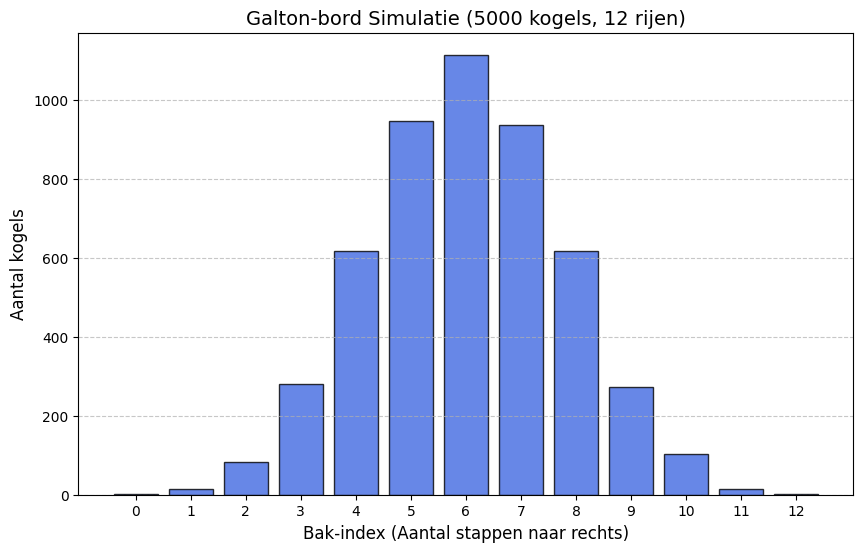

In [ ]:
# Voer de simulatie uit met 5000 kogeltjes en 12 rijen met pinnetjes
aantal_rijen = 12
aantal_kogels = 5000

resultaat_bakken = simuleer_galton(aantal_kogels, aantal_rijen)
visualiseer_galton(resultaat_bakken, aantal_rijen)

Bij een Galton-bord vallen kogeltjes van bovenaf door een raster van pinnetjes. Bij elk pinnetje heeft een kogeltje 50% kans om naar links of naar rechts te vallen. Dit proces herhaalt zich voor een aantal rijen, waarna de kogeltjes in opvangbakken terechtkomen. Volgens de centrale limietstelling zal de verdeling van de kogeltjes uiteindelijk een binomiale verdeling (die de normale verdeling benadert) vormen.

## Met tijd-vertraging

In [ ]:
import time
import random
import matplotlib.pyplot as plt

from scipy.stats import binom
from IPython import display

In [11]:
def simuleer_en_visualiseer_live(aantal_kogels=1000, aantal_rijen=12, update_interval=50):
    # Initialiseer de bakken
    bakken = [0] * (aantal_rijen + 1)
    bak_labels = list(range(len(bakken)))

    # Maak een figuur aan voor de live-animatie
    fig, ax = plt.subplots(figsize=(10, 6))

    for i in range(1, aantal_kogels + 1):
        # Simuleer het pad van één kogel
        positie = 0
        for _ in range(aantal_rijen):
            if random.random() < 0.5:
                positie += 1
        bakken[positie] += 1

        # Update de visualisatie op basis van de update_interval of bij de allerlaatste kogel
        if i % update_interval == 0 or i == aantal_kogels:
            ax.clear()

            # Plot de werkelijke simulatie (staven)
            bars = ax.bar(bak_labels, bakken, color='royalblue', edgecolor='black', alpha=0.7, label='Simulatie')

            # Bereken en plot de theoretische binomiale verdeling
            # Kans p = 0.5 voor elke stap naar rechts
            theoretische_kansen = [binom.pmf(k, aantal_rijen, 0.5) for k in bak_labels]
            theoretische_aantallen = [p_kans * i for p_kans in theoretische_kansen]
            ax.plot(bak_labels, theoretische_aantallen, color='crimson', marker='o', linewidth=2, label='Theoretische Binomiale Verdeling')

            # Voeg labels, legenda en titels toe
            ax.set_title(f"Live Galton-bord Simulatie ({i} / {aantal_kogels} kogels, {aantal_rijen} rijen)", fontsize=14)
            ax.set_xlabel("Bak-index (Aantal stappen naar rechts)", fontsize=12)
            ax.set_ylabel("Aantal kogels", fontsize=12)
            ax.set_xticks(bak_labels)
            ax.grid(axis='y', linestyle='--', alpha=0.7)
            ax.legend(loc='upper left')

            # Bepaal een dynamische y-as limiet zodat de grafiek niet constant verspringt
            ax.set_ylim(0, max(max(bakken + theoretische_aantallen) * 1.1, 10))

            # Ververs het display in Colab
            display.clear_output(wait=True)
            display.display(fig)
            time.sleep(0.10) # Korte pauze voor een vloeiend effect

    plt.close(fig) # Sluit de statische figuur om dubbele weergave te voorkomen

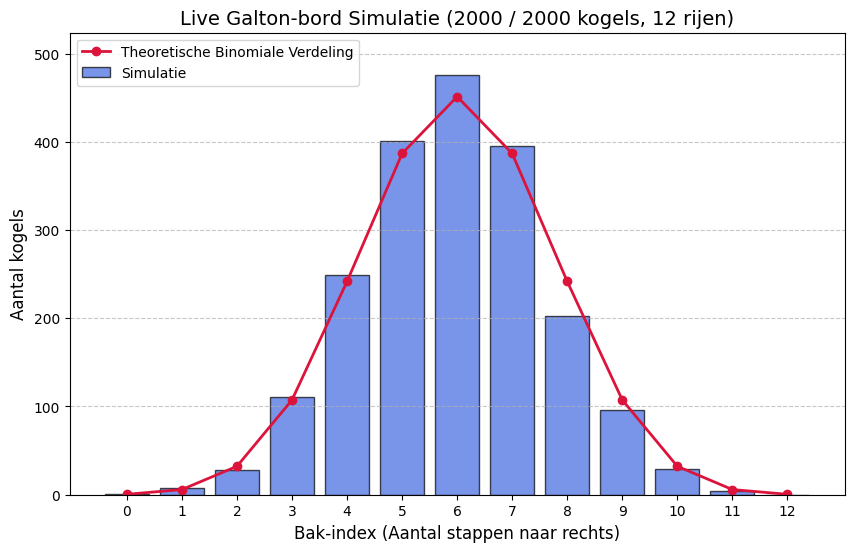

In [12]:
# Start de live simulatie met 2000 kogeltjes en bekijk de live-update
simuleer_en_visualiseer_live(aantal_kogels=2000, aantal_rijen=12, update_interval=25)

In [13]:
# Aantal rijen (n) en de kans per stap naar rechts (p)
n = 12
p = 0.5

# Berekening van het theoretische gemiddelde en de standaarddeviatie van een binomiale verdeling
gemiddelde = n * p
variantie = n * p * (1 - p)
sd = variantie ** 0.5

# Berekening van de kansen voor de uiterste bakken
kans_bak_0 = binom.pmf(0, n, p)
kans_bak_12 = binom.pmf(12, n, p)

print(f"Theoretische statistieken voor het Galton-bord (n = {n}):")
print(f"- Gemiddelde bak-index (μ): {gemiddelde:.1f}")
print(f"- Standaarddeviatie (σ): {sd:.4f}")
print(f"- Kans op bak 0: {kans_bak_0:.6f} ({kans_bak_0 * 100:.4f}%)")
print(f"- Kans op bak 12: {kans_bak_12:.6f} ({kans_bak_12 * 100:.4f}%)")

Theoretische statistieken voor het Galton-bord (n = 12):
- Gemiddelde bak-index (μ): 6.0
- Standaarddeviatie (σ): 1.7321
- Kans op bak 0: 0.000244 (0.0244%)
- Kans op bak 12: 0.000244 (0.0244%)
